# 02 · EDA & Cleaning
Continues from `01_soql_ingestion.ipynb`: loads the raw snapshot from `data/raw/`; the cleaned dataset is saved to `data/processed/` at the end.

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import sys
from google.colab import drive

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/Coursera/projects_github/nyc_taxi_2023_v2')

from src.colab_setup import setup_environment
setup_environment()

# Now all your other src modules work cleanly:
from src.api import *
from src.features import *
from src.eda import *

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

 - /content/drive/MyDrive/Coursera/projects_github/nyc_taxi_2023_v3
Environment ready. Project root: /content


In [8]:
df_local = load_raw_data()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   vendorid               50000 non-null  int64  
 1   tpep_pickup_datetime   50000 non-null  object 
 2   tpep_dropoff_datetime  50000 non-null  object 
 3   passenger_count        50000 non-null  float64
 4   trip_distance          50000 non-null  float64
 5   ratecodeid             50000 non-null  float64
 6   store_and_fwd_flag     50000 non-null  object 
 7   pulocationid           50000 non-null  int64  
 8   dolocationid           50000 non-null  int64  
 9   payment_type           50000 non-null  int64  
 10  fare_amount            50000 non-null  float64
 11  extra                  50000 non-null  float64
 12  mta_tax                50000 non-null  float64
 13  tip_amount             50000 non-null  float64
 14  tolls_amount           50000 non-null  float64
 15  im

In [9]:
df_local.shape

(50000, 17)

In [10]:
data_quality_report(df_local)

Shape of dataframe: (50000, 17)
Shape of dataframe with duplicates dropped: (50000, 17)
Total count of missing values: 0
Missing values per column:


,0
vendorid,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,0
trip_distance,0
ratecodeid,0
store_and_fwd_flag,0
pulocationid,0
dolocationid,0
payment_type,0


In [11]:
df_local.describe()

,vendorid,passenger_count,trip_distance,ratecodeid,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.746080,1.557980,4.051155,1.450500,159.115080,156.334600,1.295940,20.758118,1.192998,0.479952,3.388289,0.664424,0.977092,29.174196
std,0.435257,1.030427,4.849091,5.640956,67.879881,74.345878,0.556099,20.446968,1.473999,0.120499,4.423309,2.434152,0.205506,24.874490
min,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,-346.000000,-6.000000,-0.500000,-0.900000,-20.750000,-1.000000,-351.000000
25%,1.000000,1.000000,1.210000,1.000000,112.000000,97.000000,1.000000,9.300000,0.000000,0.500000,0.000000,0.000000,1.000000,15.120000
50%,2.000000,1.000000,2.200000,1.000000,161.000000,158.000000,1.000000,14.200000,1.000000,0.500000,2.520000,0.000000,1.000000,21.000000
75%,2.000000,2.000000,4.600000,1.000000,231.000000,233.000000,2.000000,24.700000,2.500000,0.500000,4.450000,0.000000,1.000000,32.760000
max,2.000000,6.000000,105.550000,99.000000,265.000000,265.000000,4.000000,454.500000,9.750000,0.800000,211.500000,49.850000,1.000000,472.250000


In [12]:
df_local.columns

Index(['vendorid', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'ratecodeid', 'store_and_fwd_flag',
       'pulocationid', 'dolocationid', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount'],
      dtype='object')

###Convert pickup and dropoff columns to datetime

In [13]:
# Check the format of the data
df_local['tpep_dropoff_datetime'][0]

'2023-01-01 00:40:36'

In [14]:
df_local = convert_datetime_columns(df_local)

df_local.head(3)

Data type of tpep_pickup_datetime before: object
Data type of tpep_dropoff_datetime before: object
Data type of tpep_pickup_datetime after: datetime64[ns]
Data type of tpep_dropoff_datetime after: datetime64[ns]


,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2,2023-01-01 00:32:10,2023-01-01 00:40:36,1.0,0.97,1.0,N,161,141,2,9.3,1.0,0.5,0.0,0.0,1.0,14.3
1,2,2023-01-01 00:55:08,2023-01-01 01:01:27,1.0,1.10,1.0,N,43,237,1,7.9,1.0,0.5,4.0,0.0,1.0,16.9
2,2,2023-01-01 00:25:04,2023-01-01 00:37:49,1.0,2.51,1.0,N,48,238,1,14.9,1.0,0.5,15.0,0.0,1.0,34.9


### Task 2c. Create duration column

In [15]:
df_local = add_duration(df_local)

In [16]:
df_local['duration'].head()

,duration
0,8.433333
1,6.316667
2,12.750000
3,9.616667
4,10.833333


In [17]:
df_local.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   vendorid               50000 non-null  int64         
 1   tpep_pickup_datetime   50000 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  50000 non-null  datetime64[ns]
 3   passenger_count        50000 non-null  float64       
 4   trip_distance          50000 non-null  float64       
 5   ratecodeid             50000 non-null  float64       
 6   store_and_fwd_flag     50000 non-null  object        
 7   pulocationid           50000 non-null  int64         
 8   dolocationid           50000 non-null  int64         
 9   payment_type           50000 non-null  int64         
 10  fare_amount            50000 non-null  float64       
 11  extra                  50000 non-null  float64       
 12  mta_tax                50000 non-null  float64       
 13  t

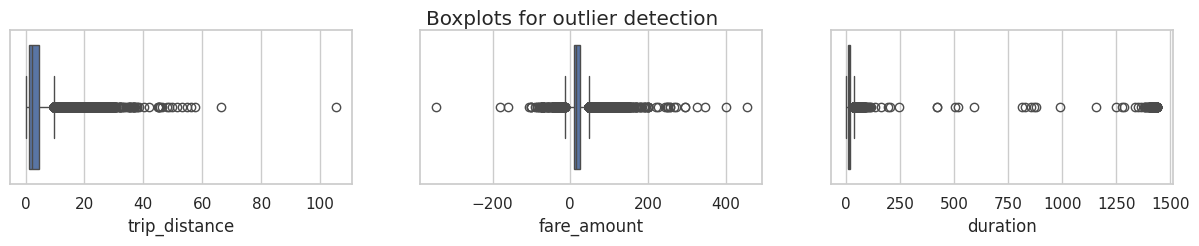

In [18]:
plot_boxplots(df_local)

In [19]:
df_local.isnull().sum()

,0
vendorid,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,0
trip_distance,0
ratecodeid,0
store_and_fwd_flag,0
pulocationid,0
dolocationid,0
payment_type,0


In [20]:
df_local

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,duration
0,2,2023-01-01 00:32:10,2023-01-01 00:40:36,1.0,0.97,1.0,N,161,141,2,9.3,1.00,0.5,0.00,0.00,1.0,14.30,8.433333
1,2,2023-01-01 00:55:08,2023-01-01 01:01:27,1.0,1.10,1.0,N,43,237,1,7.9,1.00,0.5,4.00,0.00,1.0,16.90,6.316667
2,2,2023-01-01 00:25:04,2023-01-01 00:37:49,1.0,2.51,1.0,N,48,238,1,14.9,1.00,0.5,15.00,0.00,1.0,34.90,12.750000
3,1,2023-01-01 00:03:48,2023-01-01 00:13:25,0.0,1.90,1.0,N,138,7,1,12.1,7.25,0.5,0.00,0.00,1.0,20.85,9.616667
4,2,2023-01-01 00:10:29,2023-01-01 00:21:19,1.0,1.43,1.0,N,107,79,1,11.4,1.00,0.5,3.28,0.00,1.0,19.68,10.833333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,2,2023-01-01 16:42:05,2023-01-01 17:04:13,1.0,5.57,1.0,N,138,202,1,26.8,5.00,0.5,4.00,0.00,1.0,38.55,22.133333
49996,2,2023-01-01 16:06:08,2023-01-01 16:51:32,2.0,17.71,2.0,N,132,246,1,70.0,0.00,0.5,16.36,6.55,1.0,98.16,45.400000
49997,2,2023-01-01 16:57:07,2023-01-01 17:36:01,1.0,19.88,2.0,N,132,263,1,70.0,0.00,0.5,16.36,6.55,1.0,98.16,38.900000
49998,2,2023-01-01 16:30:26,2023-01-01 16:37:09,1.0,1.38,1.0,N,236,238,1,9.3,0.00,0.5,3.33,0.00,1.0,16.63,6.716667


In [21]:
df_local.duplicated().sum()

np.int64(0)

In [22]:
df_local['passenger_count'].value_counts(normalize=True).sort_index() * 100

,proportion
passenger_count,
0.0,1.920
1.0,63.852
2.0,21.286
3.0,6.194
4.0,3.946
5.0,1.804
6.0,0.998


#### Passenger Count Anomaly & Filtering Logic

Based on our exploratory data analysis, we observe several anomalies in the `passenger_count` column:
- **`passenger_count = 0` (1.92% of the data):** Illogical for a taxi ride to have zero passengers; likely administrative or system error records.
- **`passenger_count > 4` (~2.80% of the data):** Trips containing 5 or 6 passengers represent rare events that often violate standard passenger limits depending on the vehicle type.

Since the combined contribution of these atypical records (`0`, `5`, and `6` passengers) constitutes a minor fraction (~4.7%) of our total dataset, we will filter them out. Removing these anomalies cleanses the data, reducing noise and ensuring higher quality downstream inputs for both statistical testing and machine learning modeling.

In [23]:
df_local['trip_distance'].value_counts(normalize=True).sort_index() * 100

,proportion
trip_distance,
0.00,1.968
0.01,0.100
0.02,0.082
0.03,0.060
0.04,0.036
...,...
54.70,0.002
56.20,0.002
57.49,0.002


In [24]:
df_local['trip_distance'].describe()

,trip_distance
count,50000.000000
mean,4.051155
std,4.849091
min,0.000000
25%,1.210000
50%,2.200000
75%,4.600000
max,105.550000


In [25]:
df_clean = verify_distance_outliers(df_local)

--- Outlier Verification ---
IQR: 3.39 miles (Q1: 1.21, Q3: 4.60)
Theoretical limits for normal distribution: 0.00 to 9.68 miles
Trips with 0.0 distance: 984 (1.97% of data)
Trips exceeding upper bound (9.68 miles): 5369 (10.74% of data)
99th percentile of trip distance: 20.66 miles

--- Post-cleaning Analysis ---
Original dataset size: 50000 rows
Cleaned dataset size: 48516 rows
Cleaned dataset max distance: 20.66 miles


### Data Cleaning Pipeline: Removing Anomalies and Outliers

In [26]:
df_local.duration.quantile(0.99)

np.float64(51.71766666666687)

In [27]:
df_cleaned = clean_trip_data(df_local)

--- Data Cleaning Summary ---
Original rows: 50,000
Cleaned rows:  45,852
Rows removed:  4,148 (8.30% of total data)

--- Cleaned Data Distributions ---
Passenger limits: 1.0 to 4.0 passengers
Distance limits:  0.01 to 20.66 miles
Duration limits:  0.03 to 51.72 minutes


In [29]:
df_local['fare_amount'].describe()

,fare_amount
count,50000.000000
mean,20.758118
std,20.446968
min,-346.000000
25%,9.300000
50%,14.200000
75%,24.700000
max,454.500000


<Axes: >

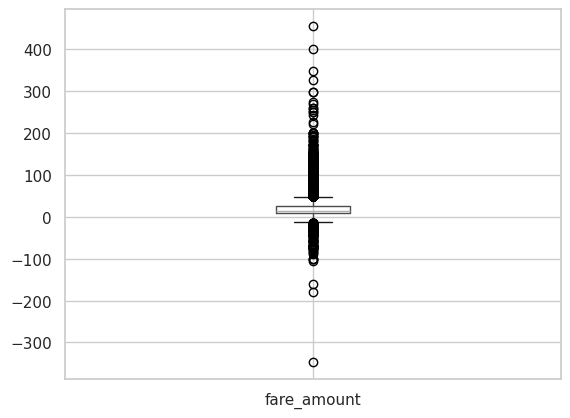

In [30]:
# To create a boxplot on a Pandas Series, use DataFrame.boxplot() and specify the column
df_local.boxplot(column='fare_amount')

Our column `fare_amount` shows that there lies some outliers plus negative values, Where  the mean and 75th percentile are 20.76 and 24.70 respectively, the max value is 454.50, Which is extreme compared to our dataset.

In [31]:
df_cleaned = clean_fare_amount(df_cleaned)

--- Fare Amount Anomaly Investigation ---
Trips with negative fares: 432 records (Min fare: $-180.0)
Trips with zero fares:     4 records
99th percentile of fare:   $75.00
Max fare in dataset:       $258.00

--- Post-Fare Cleaning Summary ---
New final dataset size:    45,192 rows
Fare range:                $0.01 to $87.40


## Data Quality Report: Fare Amount Cleanliness & Anomaly Capping

### 1. Overview & Objectives
To perform highly accurate statistical analysis and prepare features for eventual predictive modeling, we conducted an in-depth anomaly investigation on the `fare_amount` column. Our goal was to eliminate corrupt records and extreme operational outliers while maintaining the integrity of legitimate premium rides.

---

### 2. Identified Anomalies
After the passenger, distance and duration filters, the `fare_amount` values still exhibited major structural issues:
* **Negative Fares (432 Records)**: The minimum value of `-$180.00` is logically invalid for base metered rates. These entries represent credit card voids, administrative system adjustments, or customer charge disputes.
* **Zero Fares (4 Records)**: Flat `$0.00` rates represent canceled trips, promotional free rides, or computational data loss.
* **Extreme Outliers**: The maximum fare in the dataset was a massive **`$258.00`**, whereas the **99th percentile** sat comfortably at **`$75.00`**.

---

### 3. Dynamic Thresholding Selection & Mitigation Strategy
To resolve these data quality challenges without discarding important premium rides, we designed a multi-step cleaning filter:
1. **Strict Lower Bound**: Retained only records with a positive base fare (`fare_amount > 0`). This safely eliminates all negative and zero-value records.
2. **Sophisticated Upper Capping**: Instead of standard deviations or standard IQR caps (which tend to overly penalize long-distance trips), we calculated the **99.5th percentile** dynamically:
   $$\text{Upper Limit} = \text{df\_cleaned['fare\_amount'].quantile}(0.995) = \$87.40$$
   * Utilizing a **$99.5^{\text{th}}$ percentile cap** allows us to preserve high-fare airport corridors (such as flat-rate JFK Airport or Newark Airport trips) while stripping out true operational system errors.

---

### 4. Post-Cleaning Dataset Status
After executing the cleaning pipeline, the dataset is in an optimal, clean state:
* **Final Rows**: **45,192** high-quality records.
* **Base Fare Boundaries**: From **`$0.01`** up to **`$87.40`**.
* **Data Integrity**: Zero missing values, zero illogical negative transactions, and preserved true variance for A/B testing downstream.

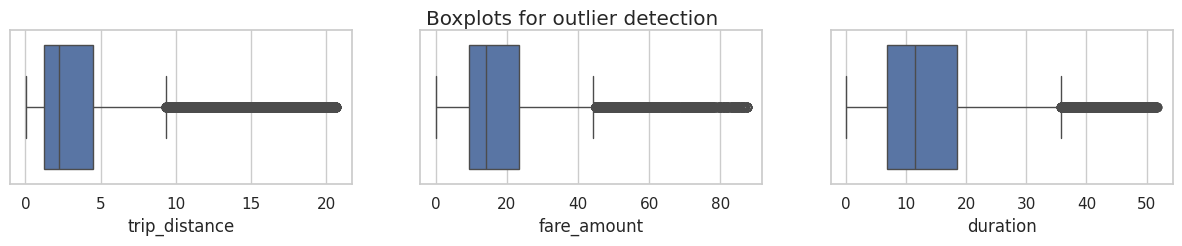

In [32]:
plot_boxplots(df_cleaned)

<Axes: >

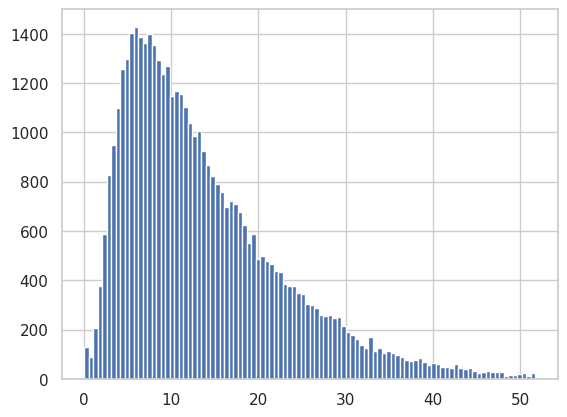

In [33]:
df_cleaned.duration.hist(bins=100)

### Save the cleaned dataset
Stored in `data/processed/` so the next notebooks can start from it.

In [34]:
save_processed_data(df_cleaned)

Saved 45,192 cleaned rows -> /content/drive/MyDrive/Coursera/projects_github/nyc_taxi_2023_v2/data/processed/nyc_yellow_taxi_2023_clean.csv


PosixPath('/content/drive/MyDrive/Coursera/projects_github/nyc_taxi_2023_v2/data/processed/nyc_yellow_taxi_2023_clean.csv')